# Knockout screen for succinate production

*E. coli* core metabolism under anaerobic growth on glucose. Every single and double gene deletion is ranked by the succinate flux it guarantees when the cell grows at its maximum rate, which is the criterion of growth-coupled production (Burgard, Pharkya and Maranas 2003; Klamt and Mahadevan 2015). All computation runs through the `rashevsky` Python API.

Model: `e_coli_core` (Orth, Fleming and Palsson 2010), as distributed by BiGG. To screen a genome-scale model, read `iML1515` from BiGG instead; the code is unchanged.

In [1]:
import itertools, pathlib, time
import matplotlib.pyplot as plt
import pandas as pd
import rashevsky as rv

root = pathlib.Path.cwd()
while not (root / "models").exists():
    root = root.parent
model = rv.read_sbml(str(root / "models" / "e_coli_core" / "e_coli_core.xml.gz"))
BIOMASS = "BIOMASS_Ecoli_core_w_GAM"
PRODUCT = "EX_succ_e"
GLUCOSE = "EX_glc__D_e"

model.set_bounds("EX_o2_e", 0.0, 1000.0)   # anaerobic
model.set_bounds(GLUCOSE, -10.0, 1000.0)
model

<Model e_coli_core: 95 reactions, 72 metabolites, 137 genes>

## Wild type

Growth-optimal fluxes, and how much succinate the cell must make at that growth rate.

In [2]:
wild = model.fba()
wild_range = model.fva(fraction=1.0, reactions=[PRODUCT])[PRODUCT]
yield_model = model.copy()
yield_model.set_objective(PRODUCT)
theoretical = yield_model.fba()["objective"]
print(f"growth {wild['objective']:.4f} 1/h")
print(f"succinate at optimal growth: {wild_range[0]:.4f} to {wild_range[1]:.4f} mmol/gDW/h")
print(f"largest succinate flux without any growth requirement: {theoretical:.2f} mmol/gDW/h")

growth 0.2117 1/h
succinate at optimal growth: 0.0000 to 0.0000 mmol/gDW/h
largest succinate flux without any growth requirement: 13.91 mmol/gDW/h


## Screen

A deletion is scored by the lower end of the succinate range at optimal growth: `guaranteed = min v_succ` subject to `v_biomass = optimum`. Deletions that stop growth (below 0.05 1/h) are discarded. Double deletions are built from genes whose single deletion leaves growth above that limit.

In [3]:
MIN_GROWTH = 0.05
started = time.time()

def score(genes):
    run = model.fba(knockout_genes=list(genes))
    growth = run["objective"]
    if run["status"] != "Optimal" or growth is None or growth < MIN_GROWTH:
        return None
    low, high = model.fva(fraction=1.0, reactions=[PRODUCT], knockout_genes=list(genes))[PRODUCT]
    return {"genes": " ".join(genes), "n": len(genes), "growth": growth, "guaranteed": low, "possible": high,
            "bpcy": growth * low / 10.0}

singles = model.single_gene_deletion()
# s0001 stands for spontaneous reactions in BiGG models. It is no gene, so it cannot be deleted.
viable = sorted(g for g, v in singles.items() if v >= MIN_GROWTH and g != "s0001")
rows = [r for r in (score((g,)) for g in viable) if r]
rows += [r for r in (score(p) for p in itertools.combinations(viable, 2)) if r]
table = pd.DataFrame(rows).sort_values(["guaranteed", "growth"], ascending=False).reset_index(drop=True)
print(f"{len(table)} viable designs from {len(viable)} genes in {time.time() - started:.1f} s")
table.head(12)

7966 viable designs from 126 genes in 32.1 s


,genes,n,growth,guaranteed,possible,bpcy
0,b0902 b3951,2,0.179985,0.678148,0.678148,0.012206
1,b0902 b3952,2,0.179985,0.678148,0.678148,0.012206
2,b0904 b2492,2,0.179985,0.678148,0.678148,0.012206
3,b0008,1,0.211663,0.000000,0.000000,0.000000
4,b0114,1,0.211663,0.000000,0.000000,0.000000
5,b0115,1,0.211663,0.000000,0.000000,0.000000
6,b0116,1,0.211663,0.000000,0.000000,0.000000
7,b0118,1,0.211663,0.000000,0.000000,0.000000
8,b0351,1,0.211663,0.000000,0.000000,0.000000
9,b0356,1,0.211663,0.000000,0.000000,0.000000


## Best design

Genes in `e_coli_core` are named by Blattner number. A pair can share its effect with others that remove the same reactions, so the table is grouped by the set of reactions each design disables.

In [4]:
best = table.iloc[0]
print("best design:", best.genes, f"growth {best.growth:.3f} 1/h, guaranteed succinate {best.guaranteed:.3f} mmol/gDW/h")
top = table[table.guaranteed > 1e-6].copy()
distinct = top.drop_duplicates(subset=["growth", "guaranteed", "possible"]).head(10)
distinct[["genes", "growth", "guaranteed", "possible", "bpcy"]]

best design: b0902 b3951 growth 0.180 1/h, guaranteed succinate 0.678 mmol/gDW/h


,genes,growth,guaranteed,possible,bpcy
0,b0902 b3951,0.179985,0.678148,0.678148,0.012206
2,b0904 b2492,0.179985,0.678148,0.678148,0.012206


## Production envelopes

Succinate against growth for the wild type and the best design. Growth coupling shows as a floor above zero at the right edge of the envelope.

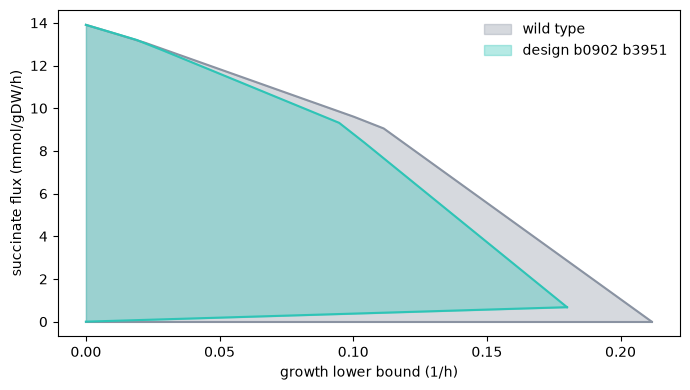

In [5]:
ranges = {}
for name, knocked in (("wild type", []), (f"design {best.genes}", best.genes.split())):
    top_growth = model.fba(knockout_genes=knocked)["objective"]
    points = []
    for fraction in [i / 19 for i in range(20)]:
        low, high = model.fva(fraction=fraction, reactions=[PRODUCT], knockout_genes=knocked)[PRODUCT]
        points.append((fraction * top_growth, low, high))
    ranges[name] = points

fig, ax = plt.subplots(figsize=(7, 4))
for (name, points), color in zip(ranges.items(), ("#8a93a2", "#2ec4b6")):
    x = [p[0] for p in points]
    ax.fill_between(x, [p[1] for p in points], [p[2] for p in points], alpha=0.35, color=color, label=name)
    ax.plot(x, [p[1] for p in points], color=color)
    ax.plot(x, [p[2] for p in points], color=color)
ax.set_xlabel("growth lower bound (1/h)")
ax.set_ylabel("succinate flux (mmol/gDW/h)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(root / "notebooks" / "knockout_screen_envelope.png", dpi=150)
plt.show()

## Check against an independent reading

Knocked-out growth rates come from `single_gene_deletion`; the same value must follow from `fba(knockout_genes=...)`, and the design's guaranteed flux must not exceed what the model can make at all.

In [6]:
for gene, value in list(singles.items())[:25]:
    direct = model.fba(knockout_genes=[gene])
    direct = direct["objective"] if direct["status"] == "Optimal" else 0.0
    assert abs(direct - value) < 1e-8, gene
assert best.guaranteed <= theoretical + 1e-9
print("checks passed")

checks passed
